In [1]:
import numpy as np
from rich import print
from contingency import Contingent
import matplotlib.pyplot as plt

from contingency.plots import PR_contour,ROC_contour

np.set_printoptions(formatter={'float_kind':"{:.5g}".format})
y_true = np.array([0,1,0,0,1]).astype(bool)
y_pred = np.array([0,1,0,1,0]).astype(bool)

y_prob = np.array([0.1,0.8,0.1,.7,.25])

# M = Contingent(y_pred = y_pred, y_true=y_true)
M = Contingent.from_scalar(y_true, y_prob)

In [8]:
M.F2
M.mcc
## maybe return a new contingent anyway? 
Contingent(y_true, M.optimize('F'))

Contingent(y_true=array([[False,  True, False, False,  True]]), y_pred=array([[False,  True, False,  True,  True]]), weights=None, TP=array([2]), FP=array([1]), FN=array([0]), TN=array([2]), PP=array([3]), PN=array([2]), P=np.int64(2), N=np.int64(3), imbalance=np.float64(1.5), PPV=masked_array(data=[0.6666666666666666],
             mask=[False],
       fill_value=1e+20), NPV=masked_array(data=[1.0],
             mask=[False],
       fill_value=1e+20), TPR=masked_array(data=[1.0],
             mask=[False],
       fill_value=1e+20), TNR=masked_array(data=[0.6666666666666666],
             mask=[False],
       fill_value=1e+20), FPR=masked_array(data=[0.33333333333333337],
             mask=[False],
       fill_value=1e+20), FNR=masked_array(data=[0.0],
             mask=[False],
       fill_value=1e+20))

np.float64(1.5)

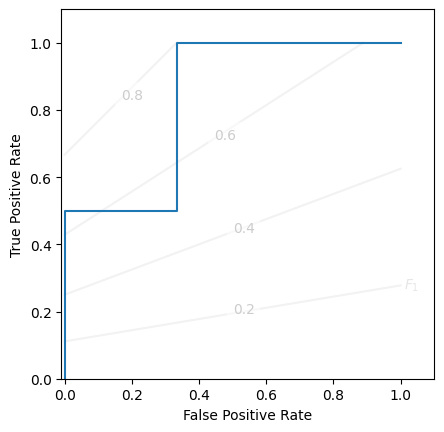

In [6]:
ROC_contour(M.imbalance)
plt.plot(1-M.TNR, M.TPR)
M.imbalance
# plt.gca().spines[['top', 'right']].set_visible(False)

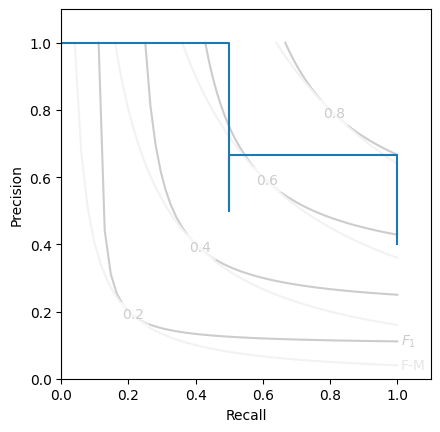

In [5]:
PR_contour()
plt.gca().set_aspect(1)
plt.step(M.recall, M.precision, where='post')

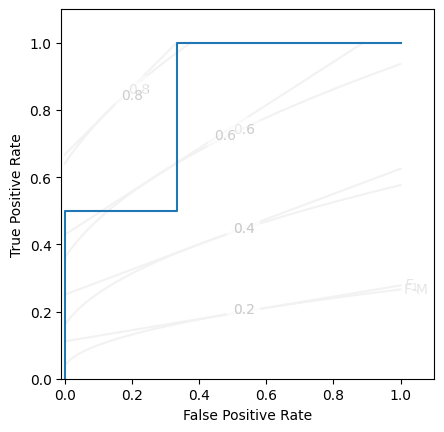

In [23]:
from typing import Literal

def ROC_contour(r, isolines: list[Literal['f1','fm']]|None='f1', ax=None):
    """Generate a nice-looking contour plot for ROC (TPR vs FNR)
    
    Args: 
        r: class imbalance ratio (required, e.g. from `Contingency.imbalance`)
        isolines: which score metric isolines to show (if any) 
        ax: existing matplotlib.pyplot.Axes to use (if any) 
    
    """
    if ax is None: 
        ax = plt.gca()
    thres = np.linspace(0.2, 0.8, num=4)
    
    def _fm_isoline_fpr(t):
        fpr_fm = np.linspace(0, np.minimum(1, (1 - t**2) / (t**2 * r)))
        tpr_fm = (t**2 + np.sqrt(t**4 + 4 * t**2 * r * fpr_fm)) / 2.
        return fpr_fm, tpr_fm

    def _f1_isoline_fpr(t):
        fpr_f1 = np.linspace(0, np.minimum(1, 2*(1-t)/(t*r)))
        tpr_f1 = np.minimum(t*(r*fpr_f1+1) / (2 - t),1)
        return fpr_f1, tpr_f1

    def _plot_isoline_func(func, name):
        lines = [(t,*func(t)) for t in thres]
        for t,fp,tp in lines: 
            (l,) = ax.plot(fp, tp, color="0.95")
            ax.annotate(
                f"{t:0.1f}",
                # xy=((fp.max()+fp.min())/2, (tp.max()+tp.min())/2),
                xy=(np.median(fp), np.median(tp)),
                color='0.8',
                bbox=dict(facecolor='white', linewidth=0, alpha=0.5)
            )
        ax.annotate(name, xy=(1.01, lines[0][-1][-1]-0.01), color='0.9')

    if 'fm' in isolines: 
        _plot_isoline_func(_fm_isoline_fpr, r"F-M")
    if 'f1' in isolines:
        _plot_isoline_func(_f1_isoline_fpr, r"$F_1$")

    ax.set(
        ylim=(0,1.1),
        xlim=(-0.01,1.1),
        ylabel='True Positive Rate',
        xlabel='False Positive Rate', 
        aspect=1,
    )
    return ax
ROC_contour(M.imbalance, isolines=['fm', 'f1'])
plt.plot(1-M.TNR, M.TPR)

In [7]:
from contingency.contingent import trapezoid
# -trapezoid(M.TPR, x=M.FPR)
M.expected('auc'), M.expected('aps')

(np.float64(0.8333333333333333), np.float64(0.8333333333333333))

masked_array(data=[1.0, 1.0, 0.33333333333333337, 0.33333333333333337,
                   0.0, 0.0],
             mask=[False, False, False, False, False, False],
       fill_value=1e+20)